# CS781 Phase 1 lightweight retention

Efficient Transformer using multi-scale RetNet-style retention, RoPE, RMSNorm, and GeGLU.

In [1]:
!pip install ijson --break-system-packages -q
import os, math, json, time, random, zipfile, csv
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import login, hf_hub_download

                                                               
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
hf_token = user_secrets.get_secret("HuggingFace")


DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_GPUS = torch.cuda.device_count()
print(DEVICE, NUM_GPUS)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 5.5 MB/s eta 0:00:00
cuda 2


In [2]:
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
DATA_SOURCES = [
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

                                                                                                 
ARCH_NAME = "retention_lite"

                                                                                                                                         
                                                                                                      
EXISTING_TOKENIZER = None

BPE_VOCAB_SIZE = 12000
BPE_TRAIN_CHARS = 8000000
MAX_BPE_WORDS = 100000

TRAIN_TOKENS = 200000000                                                                         
VAL_TOKENS = 5000000

                                                                                                  
BLOCK_SIZE = 1024

                                                                                                                                       
                                                                
MICRO_BATCH_SIZE = 8
GRAD_ACCUM_STEPS = 2

                                                                                                                        
                                                                                                                            
TIME_BUDGET_HOURS = 8.0
TIME_BUDGET_SECONDS = TIME_BUDGET_HOURS * 3600
TRAIN_STEPS = 12000                                            
EVAL_EVERY = 500
WARMUP_STEPS = 300
LR = 5e-4
WEIGHT_DECAY = 0.1

                                                                                                           
D_MODEL = 640
N_LAYERS = 12
N_HEADS = 10                                                                            
D_FF = 1792
DROPOUT = 0.1

CHUNK_SIZE = 128                                                                                            
ROPE_BASE = 10000.0
MAX_POSITIONS = 4096                                                                                  

TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 400
TEMPERATURE = 0.8
TOP_P = 0.95
CHECKPOINT_EVERY = 500

_data_tag = "-".join(s.split("/")[-1].replace(".json", "") for s in DATA_SOURCES)
RUN_ID = f"{ARCH_NAME}_{_data_tag}"
OUTPUT_DIR = f"/kaggle/working/cs781_phase1/{RUN_ID}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TOKENIZER_PATH = os.path.join(OUTPUT_DIR, "bpe_tokenizer.json")
TOKENIZED_CACHE_PATH = os.path.join(OUTPUT_DIR, "tokenized_corpus.pt")
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "checkpoint.pt")
MODEL_PATH = os.path.join(OUTPUT_DIR, "model.pt")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
HELDOUT_TRUTH_PATH = os.path.join(OUTPUT_DIR, "heldout_truth.json")
HELDOUT_PRED_PATH = os.path.join(OUTPUT_DIR, "heldout_prediction.json")
LOG_PATH = "/kaggle/working/cs781_phase1/experiment_log.csv"

print(RUN_ID)


retention_lite_train_supreme_court-train_acts-train_high_courts-train_tribunals


In [3]:
def download(path):
    return hf_hub_download(repo_id=HF_DATASET_REPO, filename=path, repo_type="dataset", token=hf_token)

train_file_paths = [download(p) for p in DATA_SOURCES]
test_file_path = download(TEST_FILE)

import ijson

CHARS_PER_TOKEN_EST = 4                                                                                    
CHAR_BUDGET = (TRAIN_TOKENS + VAL_TOKENS) * CHARS_PER_TOKEN_EST + BPE_TRAIN_CHARS + 5000000
MIN_RECORDS = 1000

def stream_records(path, char_budget, min_records):
    collected_chars, n = 0, 0
    with open(path, "rb") as f:
        for rec in ijson.items(f, "item"):
            yield rec
            collected_chars += len(rec.get("text", ""))
            n += 1
            if collected_chars >= char_budget and n >= min_records:
                return

per_file_budget = CHAR_BUDGET // len(train_file_paths)
per_file_min = max(MIN_RECORDS // len(train_file_paths), 300)

records = []
for p in train_file_paths:
    records.extend(stream_records(p, per_file_budget, per_file_min))

random.Random(SEED).shuffle(records)

N_HELDOUT_DOCS = 200
heldout_records = records[-N_HELDOUT_DOCS:]
train_pool_records = records[:-N_HELDOUT_DOCS]
full_train_text = "\n".join(r["text"] for r in train_pool_records)
print(len(records), len(full_train_text))

Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_high_cou(…): reconstructing file:   0%|          |  0.00B / 10.7GB            

Phase_1_Pretraining/Train/train_high_cou(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_tribunal(…): reconstructing file:   0%|          |  0.00B / 6.48GB            

Phase_1_Pretraining/Train/train_tribunal(…): downloading bytes:           |  0.00B            

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

109385 831387231


In [4]:
class ByteLevelBPETokenizer:
    SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]

    def __init__(self):
        self.merges = {}
        self.id_to_bytes = {i: bytes([i]) for i in range(256)}
        self.special_to_id = {}
        for i, tok in enumerate(self.SPECIAL_TOKENS):
            tid = 256 + i
            self.special_to_id[tok] = tid
            self.id_to_bytes[tid] = tok.encode("utf-8")

    @property
    def vocab_size(self):
        return len(self.id_to_bytes)

    @staticmethod
    def _pair_counts(sequences):
        counts = {}
        for seq, freq in sequences:
            for pair in zip(seq, seq[1:]):
                counts[pair] = counts.get(pair, 0) + freq
        return counts

    @staticmethod
    def _apply_merge(seq, pair, new_id):
        out, i = [], 0
        while i < len(seq):
            if i < len(seq) - 1 and (seq[i], seq[i + 1]) == pair:
                out.append(new_id); i += 2
            else:
                out.append(seq[i]); i += 1
        return out

    def train(self, text, vocab_size, max_words=MAX_BPE_WORDS, verbose=True):
        num_merges = vocab_size - self.vocab_size
        if num_merges <= 0:
            return self

        word_freq = {}
        for word in text.split():
            word_freq[word] = word_freq.get(word, 0) + 1
        if len(word_freq) > max_words:
            word_freq = dict(sorted(word_freq.items(), key=lambda kv: -kv[1])[:max_words])
        sequences = [[list(word.encode("utf-8")), freq] for word, freq in word_freq.items()]

        next_id = self.vocab_size
        for step in range(num_merges):
            counts = self._pair_counts(sequences)
            if not counts:
                break
            best_pair = max(counts, key=counts.get)
            self.merges[best_pair] = next_id
            self.id_to_bytes[next_id] = self.id_to_bytes[best_pair[0]] + self.id_to_bytes[best_pair[1]]
            for entry in sequences:
                entry[0] = self._apply_merge(entry[0], best_pair, next_id)
            if verbose and (step + 1) % 1000 == 0:
                print(step + 1, next_id + 1)
            next_id += 1
        return self

    def _encode_word(self, word):
        seq = list(word.encode("utf-8"))
        while len(seq) > 1:
            mergeable = [p for p in zip(seq, seq[1:]) if p in self.merges]
            if not mergeable:
                break
            pair = min(mergeable, key=lambda p: self.merges[p])
            seq = self._apply_merge(seq, pair, self.merges[pair])
        seq.append(self.special_to_id["</s>"])
        return seq

    def encode(self, text):
        cache = self.__dict__.setdefault("_word_cache", {})
        ids = []
        for word in text.split():
            w = cache.get(word)
            if w is None:
                w = self._encode_word(word)
                if len(cache) < 3000000:
                    cache[word] = w
            ids.extend(w)
        return ids

    def encode_to_array(self, text, max_tokens, slice_chars=20000000):
        """Same output as the naive version, but (1) caches word -> ids and (2) processes the text in slices
        so we never materialise a list of ~100M word strings."""
        cache = self.__dict__.setdefault("_word_cache", {})
        arr = np.empty(max_tokens, dtype=np.int32)
        n, pos, L = 0, 0, len(text)
        while pos < L and n < max_tokens:
            end = min(pos + slice_chars, L)
            while end < L and not text[end].isspace():
                end += 1
            buf = []
            for word in text[pos:end].split():
                w = cache.get(word)
                if w is None:
                    w = self._encode_word(word)
                    if len(cache) < 3000000:
                        cache[word] = w
                buf.extend(w)
                if n + len(buf) >= max_tokens:
                    break
            m = min(len(buf), max_tokens - n)
            arr[n:n + m] = buf[:m]
            n += m
            pos = end
            print(f"  tokenized {n:,} / {max_tokens:,}")
        return arr[:n]

    def decode(self, ids):
        words, current = [], []
        for i in ids:
            if i == self.special_to_id["</s>"]:
                if current:
                    words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
                    current = []
            else:
                current.append(i)
        if current:
            words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
        return " ".join(words)

    def save(self, path):
        merges_serializable = {f"{a},{b}": nid for (a, b), nid in self.merges.items()}
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"merges": merges_serializable}, f)

    @classmethod
    def load(cls, path):
        tok = cls()
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        for pair_str, nid in data["merges"].items():
            a, b = (int(x) for x in pair_str.split(","))
            tok.merges[(a, b)] = nid
            tok.id_to_bytes[nid] = tok.id_to_bytes[a] + tok.id_to_bytes[b]
        return tok

In [5]:
if EXISTING_TOKENIZER and os.path.exists(EXISTING_TOKENIZER):
    tokenizer = ByteLevelBPETokenizer.load(EXISTING_TOKENIZER)
    tokenizer.save(TOKENIZER_PATH)
elif os.path.exists(TOKENIZER_PATH):
    tokenizer = ByteLevelBPETokenizer.load(TOKENIZER_PATH)
else:
    tokenizer = ByteLevelBPETokenizer().train(full_train_text[:BPE_TRAIN_CHARS], BPE_VOCAB_SIZE)
    tokenizer.save(TOKENIZER_PATH)

VOCAB_SIZE = tokenizer.vocab_size
print(VOCAB_SIZE)

1000 1260
2000 2260
3000 3260
4000 4260
5000 5260
6000 6260
7000 7260
8000 8260
9000 9260
10000 10260
11000 11260
12000


In [6]:
if os.path.exists(TOKENIZED_CACHE_PATH):
    cache = torch.load(TOKENIZED_CACHE_PATH, weights_only=False)
    train_ids, val_ids = torch.from_numpy(cache["train_ids"]), torch.from_numpy(cache["val_ids"])
else:
    all_ids = tokenizer.encode_to_array(full_train_text, TRAIN_TOKENS + VAL_TOKENS)
    split = int(len(all_ids) * (TRAIN_TOKENS / (TRAIN_TOKENS + VAL_TOKENS)))
    train_ids, val_ids = all_ids[:split].copy(), all_ids[split:].copy()
    torch.save({"train_ids": train_ids, "val_ids": val_ids}, TOKENIZED_CACHE_PATH)

del full_train_text
print(len(train_ids), len(val_ids))

def make_blocks(ids, block_size):
    n = (len(ids) // block_size) * block_size
    return torch.from_numpy(np.asarray(ids[:n], dtype=np.int64)).view(-1, block_size)

train_blocks = make_blocks(train_ids, BLOCK_SIZE)
val_blocks = make_blocks(val_ids, BLOCK_SIZE)

class BlockDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, idx):
        x = self.blocks[idx]
        return x[:-1], x[1:]

train_loader = DataLoader(BlockDataset(train_blocks), batch_size=MICRO_BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(BlockDataset(val_blocks), batch_size=MICRO_BATCH_SIZE, shuffle=False, drop_last=True)

  tokenized 7,276,659 / 205,000,000
  tokenized 14,595,814 / 205,000,000
  tokenized 21,960,513 / 205,000,000
  tokenized 29,338,708 / 205,000,000
  tokenized 36,674,815 / 205,000,000
  tokenized 44,045,001 / 205,000,000
  tokenized 51,361,459 / 205,000,000
  tokenized 58,705,323 / 205,000,000
  tokenized 66,055,443 / 205,000,000
  tokenized 73,362,092 / 205,000,000
  tokenized 80,704,587 / 205,000,000
  tokenized 88,034,516 / 205,000,000
  tokenized 95,329,383 / 205,000,000
  tokenized 102,672,394 / 205,000,000
  tokenized 110,016,055 / 205,000,000
  tokenized 117,315,986 / 205,000,000
  tokenized 124,683,424 / 205,000,000
  tokenized 132,013,778 / 205,000,000
  tokenized 139,368,039 / 205,000,000
  tokenized 146,677,303 / 205,000,000
  tokenized 154,000,408 / 205,000,000
  tokenized 161,340,617 / 205,000,000
  tokenized 168,669,870 / 205,000,000
  tokenized 176,013,008 / 205,000,000
  tokenized 183,400,135 / 205,000,000
  tokenized 190,733,876 / 205,000,000
  tokenized 198,058,962 / 

In [7]:
def split_prompt_continuation(text, prompt_words=512, cont_words=128):
    words = text.split()
    if len(words) < prompt_words + 20:
        return None
    return " ".join(words[:prompt_words]), " ".join(words[prompt_words: prompt_words + cont_words])

heldout_truth, heldout_prompts = {}, {}
for i, rec in enumerate(heldout_records):
    r = split_prompt_continuation(rec["text"])
    if r is None:
        continue
    ex_id = str(i + 1)
    heldout_prompts[ex_id] = {"text": r[0]}
    heldout_truth[ex_id] = {"text": r[1]}

with open(HELDOUT_TRUTH_PATH, "w", encoding="utf-8") as f:
    json.dump(heldout_truth, f, ensure_ascii=False, indent=2)
print(len(heldout_truth))

73


In [8]:
class RMSNorm(nn.Module):
    """RMS normalization without mean subtraction."""
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        rms = x.pow(2).mean(dim=-1, keepdim=True)
        return self.weight * x * torch.rsqrt(rms + self.eps)


def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)                                                                    
    return torch.cat((-x2, x1), dim=-1)


class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len, base=10000.0):
        super().__init__()
        inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2, dtype=torch.float32) / dim))
        freqs = torch.outer(torch.arange(max_seq_len, dtype=torch.float32), inv_freq)
        emb = torch.cat((freqs, freqs), dim=-1)
        self.register_buffer("cos", emb.cos()[None, None, :, :], persistent=False)
        self.register_buffer("sin", emb.sin()[None, None, :, :], persistent=False)

    def forward(self, x, offset=0):
        T = x.size(-2)
        cos = self.cos[:, :, offset:offset + T, :].to(x.dtype)
        sin = self.sin[:, :, offset:offset + T, :].to(x.dtype)
        return x * cos + rotate_half(x) * sin


class GeGLU(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.gate = nn.Linear(d_model, d_ff, bias=False)
        self.up = nn.Linear(d_model, d_ff, bias=False)
        self.down = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.down(F.gelu(self.gate(x)) * self.up(x)))


def retention_chunkwise(q, k, v, log_gamma, state=None, chunk_size=128):
    """
    Chunkwise retention (RetNet). Equivalent to the recurrence
        S_t = gamma * S_{t-1} + k_t^T v_t ,   o_t = q_t S_t
    q, k: (B,H,T,dk)   v: (B,H,T,dv)   log_gamma: (H,) (negative)   state: (B,H,dk,dv) or None
    Inside a chunk: parallel (masked, decayed q k^T) v.  Across chunks: carry the (dk x dv) state.
    Memory/compute is linear in T; decoding (T=1) is O(1) per token. No softmax.
    """
    B, H, T, dk = q.shape
    dv = v.size(-1)
    if state is None:
        state = q.new_zeros(B, H, dk, dv)
    lg = log_gamma.view(1, H, 1, 1)
    outs = []
    for s in range(0, T, chunk_size):
        qc, kc, vc = q[:, :, s:s + chunk_size], k[:, :, s:s + chunk_size], v[:, :, s:s + chunk_size]
        L = qc.size(2)
        idx = torch.arange(L, device=q.device, dtype=q.dtype)
        diff = idx[:, None] - idx[None, :]                                          
        D = torch.exp(diff.clamp(min=0)[None, None] * lg) * (diff >= 0)                                   
        inner = ((qc @ kc.transpose(-1, -2)) * D) @ vc                                     
        q_decay = torch.exp((idx + 1).view(1, 1, L, 1) * lg)                              
        cross = (qc * q_decay) @ state                                                                        
        outs.append(inner + cross)
        k_decay = torch.exp((L - 1 - idx).view(1, 1, L, 1) * lg)                            
        state = torch.exp(L * lg) * state + (kc * k_decay).transpose(-1, -2) @ vc
    return torch.cat(outs, dim=2), state


class MultiScaleRetention(nn.Module):
    """RetNet-style multi-scale retention: per-head decay (fast ... slow), RoPE on q/k, per-head norm, swish output gate."""
    def __init__(self, d_model, n_heads, rope, chunk_size, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads, self.d_head, self.chunk_size = n_heads, d_model // n_heads, chunk_size
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.g_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.head_norm_w = nn.Parameter(torch.ones(n_heads, 1, self.d_head))
        self.rope = rope
        self.dropout = nn.Dropout(dropout)
                                                                                                 
        gamma = 1.0 - 2.0 ** (-5.0 - torch.arange(n_heads, dtype=torch.float32))
        self.register_buffer("log_gamma", torch.log(gamma), persistent=False)

    def _split(self, x):
        B, T, _ = x.shape
        return x.view(B, T, self.n_heads, self.d_head).transpose(1, 2)

    def forward(self, x, state=None, offset=0):
        B, T, C = x.shape
        q = self._split(self.q_proj(x)) * (self.d_head ** -0.5)
        k = self._split(self.k_proj(x))
        v = self._split(self.v_proj(x))
        q, k = self.rope(q, offset), self.rope(k, offset)
        with torch.autocast(device_type=x.device.type, enabled=False):                                    
            o, new_state = retention_chunkwise(q.float(), k.float(), v.float(), self.log_gamma, state, self.chunk_size)
            o = o * torch.rsqrt(o.pow(2).mean(dim=-1, keepdim=True) + 1e-6) * self.head_norm_w                      
        o = o.to(x.dtype).transpose(1, 2).contiguous().view(B, T, C)
        o = o * F.silu(self.g_proj(x))
        return self.dropout(self.out_proj(o)), new_state


class RetentionBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, rope, chunk_size, dropout):
        super().__init__()
        self.norm_ret = RMSNorm(d_model)
        self.retention = MultiScaleRetention(d_model, n_heads, rope, chunk_size, dropout)
        self.norm_ffn = RMSNorm(d_model)
        self.ffn = GeGLU(d_model, d_ff, dropout)

    def forward(self, x, state=None, offset=0):
        h, new_state = self.retention(self.norm_ret(x), state=state, offset=offset)
        x = x + h
        return x + self.ffn(self.norm_ffn(x)), new_state


class RetentionLM(nn.Module):
    """
    Efficient / lightweight Transformer: softmax attention replaced by multi-scale retention.
    Training: chunkwise-parallel, O(T) memory. Inference: constant-size recurrent state (no KV cache growth).
    """
    def __init__(self, vocab_size, d_model, n_layers, n_heads, d_ff, max_pos,
                 chunk_size=128, dropout=0.1, rope_base=10000.0, tie_weights=True):
        super().__init__()
        self.max_pos = max_pos
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.emb_dropout = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_heads, max_pos, rope_base)
        self.blocks = nn.ModuleList([RetentionBlock(d_model, n_heads, d_ff, self.rope, chunk_size, dropout) for _ in range(n_layers)])
        self.final_norm = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        if tie_weights:
            self.lm_head.weight = self.token_emb.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def _run(self, idx, states=None, offset=0):
        if offset + idx.size(1) > self.max_pos:
            raise ValueError(f"Position {offset + idx.size(1)} exceeds RoPE table size {self.max_pos}")
        x = self.emb_dropout(self.token_emb(idx))
        new_states = []
        for i, blk in enumerate(self.blocks):
            x, s = blk(x, state=None if states is None else states[i], offset=offset)
            new_states.append(s)
        return self.lm_head(self.final_norm(x)), new_states

    def forward(self, idx, targets=None):
        logits, _ = self._run(idx)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_p=0.95, eos_id=None, stop_after_eos=None):
        """Prefill prompt (chunkwise) -> recurrent decoding. Returns ONLY the new tokens."""
        self.eval()
        logits, states = self._run(idx)
        P, out, n_eos = idx.size(1), [], 0
        for t in range(max_new_tokens):
            probs = torch.softmax(logits[:, -1, :] / max(temperature, 1e-5), dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
            cumulative = torch.cumsum(sorted_probs, dim=-1)
            remove = cumulative > top_p
            remove[:, 1:] = remove[:, :-1].clone()
            remove[:, 0] = False
            sorted_probs = sorted_probs.masked_fill(remove, 0.0)
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            nxt = torch.gather(sorted_idx, -1, torch.multinomial(sorted_probs, 1))
            out.append(nxt)
            if stop_after_eos is not None and eos_id is not None and idx.size(0) == 1:
                n_eos += int(nxt.item() == eos_id)
                if n_eos >= stop_after_eos:
                    break
            if t < max_new_tokens - 1:
                logits, states = self._run(nxt, states=states, offset=P + t)
        return torch.cat(out, dim=1)


In [9]:
def build_model(arch_name):
    if arch_name == "retention_lite":
        return RetentionLM(
            vocab_size=VOCAB_SIZE, d_model=D_MODEL, n_layers=N_LAYERS, n_heads=N_HEADS, d_ff=D_FF,
            max_pos=MAX_POSITIONS, chunk_size=CHUNK_SIZE, dropout=DROPOUT, rope_base=ROPE_BASE, tie_weights=True,
        )
    raise ValueError(f"Unknown architecture: {arch_name}")


raw_model = build_model(ARCH_NAME).to(DEVICE)

n_params = sum(p.numel() for p in raw_model.parameters())
print(f"Parameters: {n_params / 1e6:.2f}M")
assert 50e6 <= n_params <= 300e6

if NUM_GPUS > 1:
    model = nn.DataParallel(raw_model)
else:
    model = raw_model


Parameters: 73.57M


### Architecture
- **Type:** efficient Transformer using multi-scale retention instead of softmax attention
- **Retention:** per-head exponential decay, RoPE on q/k, RMSNorm, and swish output gate
- **Training:** chunkwise-parallel retention with recurrent state across chunks; O(T)
- **Inference:** recurrent decoding with constant-size state per layer
- **FFN / norm:** GeGLU and pre-RMSNorm; tied embeddings; ~73.6M parameters
- **Context:** 1024 tokens
- **Budget:** wall-clock-limited training with an elapsed-time LR schedule

In [10]:
def get_lr(step, total_steps, warmup_steps, base_lr):
    if step < warmup_steps:
        return base_lr * step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * base_lr * (1 + math.cos(math.pi * progress))

def evaluate(loader, max_batches=50):
    model.eval()
    losses = []
    with torch.no_grad():
        for i, (x, y) in enumerate(loader):
            if i >= max_batches:
                break
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                _, loss = model(x, y)
                loss = loss.mean()
            losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

def save_checkpoint(path, step, train_loss_history, val_loss_history, step_history, elapsed_seconds):
    tmp_path = path + ".tmp"
    torch.save({
        "step": step, "model_state": raw_model.state_dict(), "optimizer_state": optimizer.state_dict(),
        "scaler_state": scaler.state_dict(), "train_loss_history": train_loss_history,
        "val_loss_history": val_loss_history, "step_history": step_history, "elapsed_seconds": elapsed_seconds,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "python_rng_state": random.getstate(),
        "run_config": {"ARCH_NAME": ARCH_NAME, "D_MODEL": D_MODEL, "N_LAYERS": N_LAYERS, "N_HEADS": N_HEADS,
                       "D_FF": D_FF, "BLOCK_SIZE": BLOCK_SIZE, "VOCAB_SIZE": VOCAB_SIZE, "CHUNK_SIZE": CHUNK_SIZE, "ROPE_BASE": ROPE_BASE, "ARCH_NAME": ARCH_NAME},
    }, tmp_path)
    os.replace(tmp_path, path)

def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    cfg = ckpt["run_config"]
    mismatches = [k for k, v in cfg.items() if str(v) != str(globals()[k])]
    if mismatches:
        raise ValueError(mismatches)
    raw_model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    scaler.load_state_dict(ckpt["scaler_state"])
    torch.set_rng_state(ckpt["torch_rng_state"])
    if ckpt["cuda_rng_state"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(ckpt["cuda_rng_state"])
    random.setstate(ckpt["python_rng_state"])
    return ckpt["step"], ckpt["train_loss_history"], ckpt["val_loss_history"], ckpt["step_history"], ckpt["elapsed_seconds"]


optimizer = torch.optim.AdamW(raw_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY, betas=(0.9, 0.95))
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

if os.path.exists(CHECKPOINT_PATH):
    step, train_loss_history, val_loss_history, step_history, prev_elapsed = load_checkpoint(CHECKPOINT_PATH)
else:
    step, train_loss_history, val_loss_history, step_history, prev_elapsed = 0, [], [], [], 0.0

t0 = time.time()
model.train()
def infinite_batches(loader):
    while True:
        yield from loader

data_iter = infinite_batches(train_loader)

while step < TRAIN_STEPS:
    elapsed_now = prev_elapsed + (time.time() - t0)
    if elapsed_now >= TIME_BUDGET_SECONDS:
        print("Time budget reached - stopping training.")
        break
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM_STEPS):
        x, y = next(data_iter)
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
            _, loss = model(x, y)
            loss = loss.mean() / GRAD_ACCUM_STEPS
        scaler.scale(loss).backward()
        accum_loss += loss.item()

    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(raw_model.parameters(), 1.0)
    progress = max(step / TRAIN_STEPS, elapsed_now / TIME_BUDGET_SECONDS)                                                
    lr_now = get_lr(progress * TRAIN_STEPS, TRAIN_STEPS, WARMUP_STEPS, LR)
    for g in optimizer.param_groups:
        g["lr"] = lr_now
    scaler.step(optimizer)
    scaler.update()
    step += 1

    if step % 50 == 0:
        train_loss_history.append(accum_loss); step_history.append(step)
        print(step, accum_loss, lr_now)

    if step % EVAL_EVERY == 0 or step == TRAIN_STEPS:
        v_loss = evaluate(val_loader)
        val_loss_history.append((step, v_loss))
        print("eval", step, v_loss, math.exp(v_loss))

    if step % CHECKPOINT_EVERY == 0 or step == TRAIN_STEPS:
        elapsed = prev_elapsed + (time.time() - t0)
        save_checkpoint(CHECKPOINT_PATH, step, train_loss_history, val_loss_history, step_history, elapsed)

training_time = prev_elapsed + (time.time() - t0)
print(training_time / 3600)
                                                                                                   
if not val_loss_history or val_loss_history[-1][0] != step:
    val_loss_history.append((step, evaluate(val_loader)))
save_checkpoint(CHECKPOINT_PATH, step, train_loss_history, val_loss_history, step_history, training_time)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


50 4.9362287521362305 8.166666666666665e-05
100 4.032896280288696 0.000165
150 3.980844497680664 0.0002483333333333333
200 3.803194761276245 0.00033166666666666663
250 3.7356996536254883 0.000415
300 3.5432599782943726 0.0004983333333333333
350 3.54616916179657 0.0004999783616605279
400 3.47573459148407 0.000499911675161953
450 3.1657376289367676 0.0004997999435117859
500 3.4041401147842407 0.0004996431868490185
eval 500 3.2521237182617186 25.845169533772527
550 2.938530445098877 0.0004994414334281432
600 3.1281388998031616 0.0004991947196140618
650 2.9864104986190796 0.0004989030898755295
700 2.8059864044189453 0.0004985665967771405
750 2.779515266418457 0.0004981853009698533
800 2.7446868419647217 0.0004977592711800585
850 2.6834607124328613 0.0004972885841971918
900 2.4867501258850098 0.0004967733248598926
950 2.6448484659194946 0.0004962135860407124
1000 2.514518618583679 0.0004956094686293754
eval 1000 2.58357928276062 13.24445908573013
1050 2.417580246925354 0.0004949610815145934

1.6234340968728065 5.07047294795523


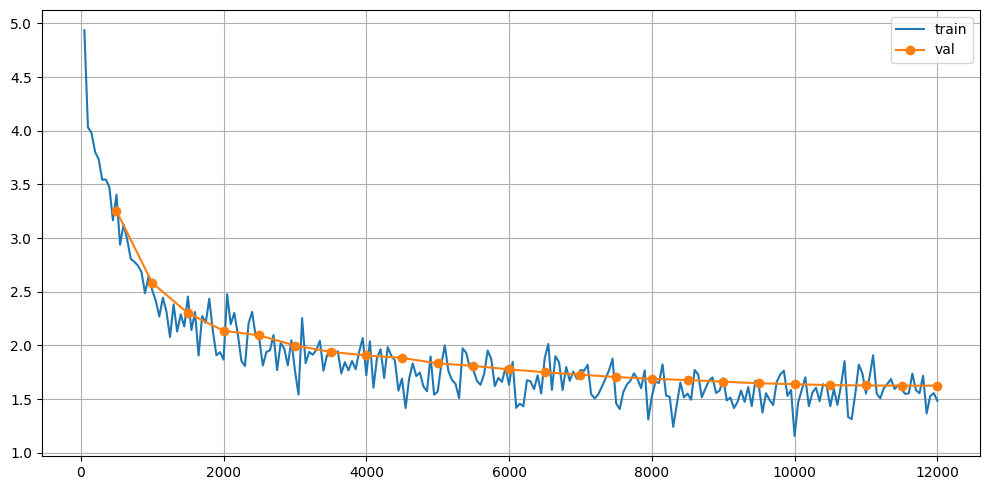

In [11]:
import matplotlib.pyplot as plt

final_val_loss = evaluate(val_loader, max_batches=200)
final_val_ppl = math.exp(final_val_loss)
print(final_val_loss, final_val_ppl)

plt.figure(figsize=(10, 5))
plt.plot(step_history, train_loss_history, label="train")
if val_loss_history:
    vs, vl = zip(*val_loss_history)
    plt.plot(vs, vl, label="val", marker="o")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

In [12]:
torch.save({
    "state_dict": raw_model.state_dict(),
    "config": {"vocab_size": VOCAB_SIZE, "d_model": D_MODEL, "n_layers": N_LAYERS, "n_heads": N_HEADS,
               "d_ff": D_FF, "max_pos": MAX_POSITIONS, "train_context": BLOCK_SIZE, "chunk_size": CHUNK_SIZE,
               "dropout": DROPOUT, "rope_base": ROPE_BASE, "arch_name": ARCH_NAME},
}, MODEL_PATH)


In [13]:
def trim_to_words(text, n_words):
    return " ".join(text.split()[:n_words])

EOS_ID = tokenizer.special_to_id["</s>"]

                                                                                                                  
                                                                                                                                        
PROMPT_TOKENS = BLOCK_SIZE - MAX_GENERATION_TOKENS

def generate_continuation(prompt_text, max_new_tokens=MAX_GENERATION_TOKENS):
    prompt_ids = tokenizer.encode(prompt_text)[-PROMPT_TOKENS:]
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)
    out = raw_model.generate(idx, max_new_tokens=max_new_tokens, temperature=TEMPERATURE, top_p=TOP_P,
                             eos_id=EOS_ID, stop_after_eos=TARGET_GENERATION_WORDS + 5)                      
    new_text = tokenizer.decode(out[0].tolist())                                                
    return trim_to_words(new_text, TARGET_GENERATION_WORDS)

def generate_for_dataset(prompt_dict):
    predictions = {}
    for i, (ex_id, rec) in enumerate(prompt_dict.items()):
        predictions[ex_id] = {"text": generate_continuation(rec["text"])}
        if (i + 1) % 25 == 0:
            print(i + 1, len(prompt_dict))
    return predictions

raw_model.eval()


RetentionLM(
  (token_emb): Embedding(12000, 640)
  (emb_dropout): Dropout(p=0.1, inplace=False)
  (rope): RotaryEmbedding()
  (blocks): ModuleList(
    (0-11): 12 x RetentionBlock(
      (norm_ret): RMSNorm()
      (retention): MultiScaleRetention(
        (q_proj): Linear(in_features=640, out_features=640, bias=False)
        (k_proj): Linear(in_features=640, out_features=640, bias=False)
        (v_proj): Linear(in_features=640, out_features=640, bias=False)
        (g_proj): Linear(in_features=640, out_features=640, bias=False)
        (out_proj): Linear(in_features=640, out_features=640, bias=False)
        (rope): RotaryEmbedding()
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (norm_ffn): RMSNorm()
      (ffn): GeGLU(
        (gate): Linear(in_features=640, out_features=1792, bias=False)
        (up): Linear(in_features=640, out_features=1792, bias=False)
        (down): Linear(in_features=1792, out_features=640, bias=False)
        (dropout): Dropout(p=0.1, inpl

In [14]:
heldout_preds = generate_for_dataset(heldout_prompts)
with open(HELDOUT_PRED_PATH, "w", encoding="utf-8") as f:
    json.dump(heldout_preds, f, ensure_ascii=False, indent=2)

25 73
50 73


In [15]:
!pip install bert-score --break-system-packages -q
!python /kaggle/input/datasets/adityakumar344/evaluate-phase1-script/evaluate_phase1.py --truth {HELDOUT_TRUTH_PATH} --prediction {HELDOUT_PRED_PATH}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.6 MB/s eta 0:00:00
python3: can't open file '/kaggle/input/datasets/adityakumar344/evaluate-phase1-script/evaluate_phase1.py': [Errno 2] No such file or directory


In [16]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

official_predictions = generate_for_dataset(test_data)
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(official_predictions, f, ensure_ascii=False, indent=2)

25 1000
50 1000
75 1000
100 1000
125 1000
150 1000
175 1000
200 1000
225 1000
250 1000
275 1000
300 1000
325 1000
350 1000
375 1000
400 1000
425 1000
450 1000
475 1000
500 1000
525 1000
550 1000
575 1000
600 1000
625 1000
650 1000
675 1000
700 1000
725 1000
750 1000
775 1000
800 1000
825 1000
850 1000
875 1000
900 1000
925 1000
950 1000
975 1000
1000 1000


In [17]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")
print(SUBMISSION_ZIP)

/kaggle/working/cs781_phase1/retention_lite_train_supreme_court-train_acts-train_high_courts-train_tribunals/submission.zip


In [18]:
def log_run():
    row = {
        "run_id": RUN_ID, "arch": ARCH_NAME, "data_sources": ";".join(DATA_SOURCES),
        "vocab_size": VOCAB_SIZE, "train_tokens": len(train_ids), "block_size": BLOCK_SIZE,
        "d_model": D_MODEL, "n_layers": N_LAYERS, "n_heads": N_HEADS, "chunk_size": CHUNK_SIZE, "d_ff": D_FF,
        "params_M": round(n_params / 1e6, 2), "train_steps": TRAIN_STEPS,
        "final_val_loss": round(final_val_loss, 6), "final_val_ppl": round(final_val_ppl, 4),
        "training_hours": round(training_time / 3600, 3),
    }
    write_header = not os.path.exists(LOG_PATH)
    with open(LOG_PATH, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(row.keys()))
        if write_header:
            writer.writeheader()
        writer.writerow(row)

log_run()